In [1]:
import numpy as np
import random
from tqdm import *
from itertools import cycle, count
import gym
from RLHelper import *

>> 최적의 가치/Q 함수, 정책: 동적 계획법 가치 반복
Optimal state-value function:
| 00  0.542 | 01 0.4988 | 02 0.4707 | 03 0.4569 |
| 04 0.5585 |           | 06 0.3583 |           |
| 08 0.5918 | 09 0.6431 | 10 0.6152 |           |
|           | 13 0.7417 | 14 0.8628 |           |
정책:
| 00      < | 01      ^ | 02      ^ | 03      ^ |
| 04      < |           | 06      < |           |
| 08      ^ | 09      v | 10      < |           |
|           | 13      > | 14      v |           |


 19%|██████████████▎                                                            | 1905/10000 [00:00<00:02, 3802.14it/s]C:\Users\kuroc\AppData\Local\Temp\ipykernel_23656\2362316079.py:43: RuntimeWarning: overflow encountered in scalar add
  Q[state][action] += alphas[e] * td_error
C:\Users\kuroc\AppData\Local\Temp\ipykernel_23656\2362316079.py:43: RuntimeWarning: invalid value encountered in scalar add
  Q[state][action] += alphas[e] * td_error
C:\Users\kuroc\AppData\Local\Temp\ipykernel_23656\2362316079.py:42: RuntimeWarning: invalid value encountered in scalar subtract
  td_error = td_target - Q[state][action]
C:\Users\kuroc\AppData\Local\Temp\ipykernel_23656\2362316079.py:43: RuntimeWarning: overflow encountered in scalar multiply
  Q[state][action] += alphas[e] * td_error

 21%|███████████████▍                                                           | 2061/10000 [00:00<00:01, 4072.49it/s]C:\Users\kuroc\AppData\Local\Temp\ipykernel_23656\2362316079.py:42: RuntimeWarning: overflow e

State-value function found by Sarsa:
| 00    nan | 01    nan | 02    nan | 03    nan |
| 04    nan |           | 06    nan |           |
| 08    nan | 09    nan | 10    nan |           |
|           | 13    nan | 14    nan |           |
Optimal state-value function:
| 00  0.542 | 01 0.4988 | 02 0.4707 | 03 0.4569 |
| 04 0.5585 |           | 06 0.3583 |           |
| 08 0.5918 | 09 0.6431 | 10 0.6152 |           |
|           | 13 0.7417 | 14 0.8628 |           |
State-value function errors:
| 00    nan | 01    nan | 02    nan | 03    nan |
| 04    nan |           | 06    nan |           |
| 08    nan | 09    nan | 10    nan |           |
|           | 13    nan | 14    nan |           |
State-value function RMSE: nan
Sarsa action-value function:
nan | nan | nan | nan  (Optimal: 0.5420259308172148)
nan | nan | nan | nan  (Optimal: 0.34347360841249885)
nan | nan | nan | nan  (Optimal: 0.43818949199752155)
nan | nan | nan | nan  (Optimal: 0.30609063748462567)
nan | nan | nan | nan  (Optim

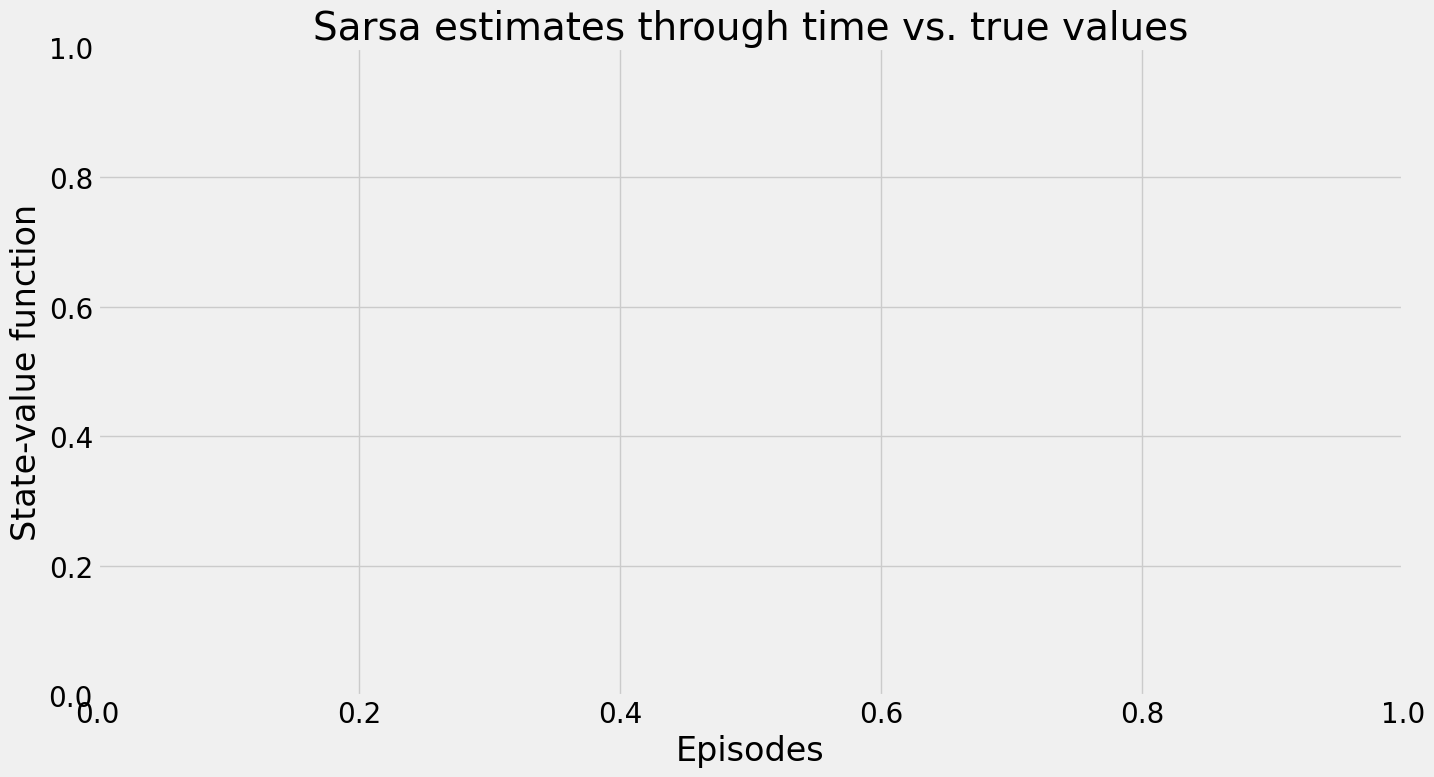

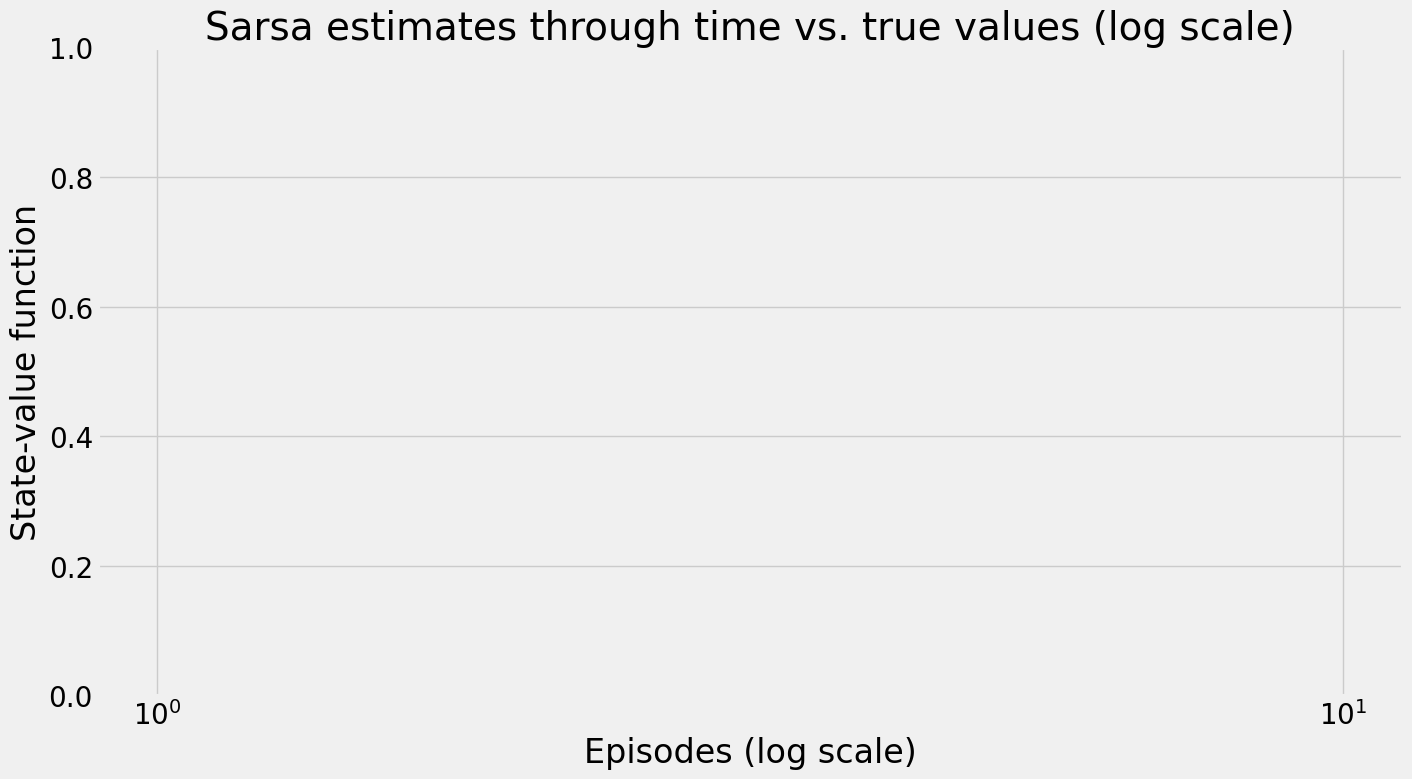

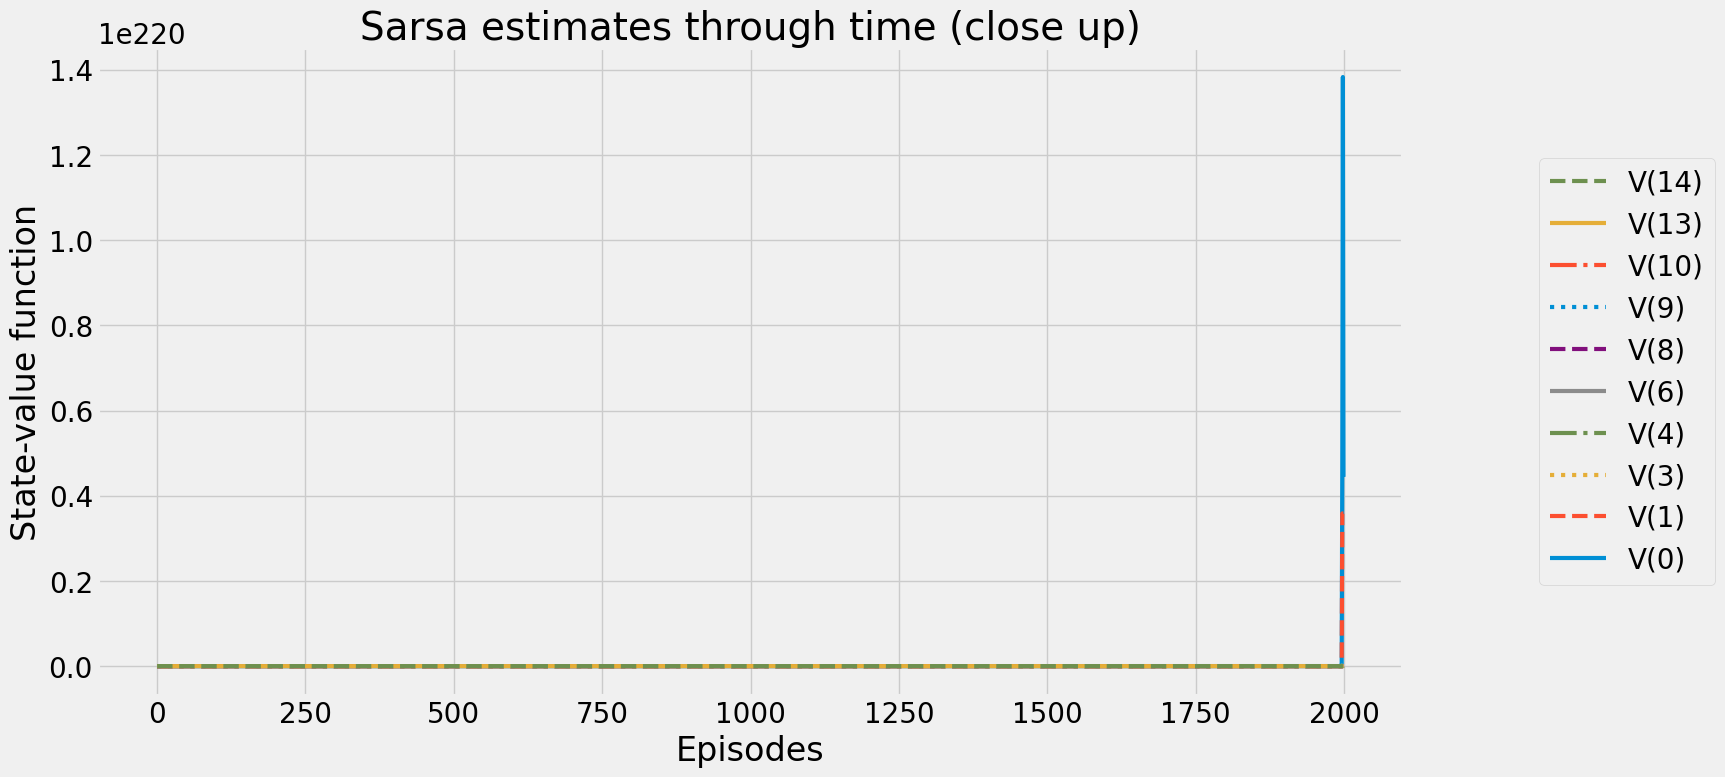

In [8]:
import numpy as np
import random
from tqdm import tqdm
from itertools import cycle
import gym
from RLHelper import *

# 학습률 감소 스케줄 함수
def decay_schedule(init_value, min_value, decay_ratio, max_steps, log_start=-2, log_base=10):
    decay_steps = int(max_steps * decay_ratio)
    alphas = np.logspace(log_start, 0, decay_steps, base=log_base)
    alphas = init_value * alphas / alphas[0]
    alphas = np.concatenate((alphas, np.full(max_steps - decay_steps, min_value)))
    return alphas

# SARSA 알고리즘
def sarsa(env, gamma=1.0, init_alpha=0.5, min_alpha=0.01, alpha_decay_ratio=0.5, init_epsilon=1.0, min_epsilon=0.1, epsilon_decay_ratio=0.9, n_episodes=3000):
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.zeros((nS, nA), dtype=np.float64)
    Q_track = np.zeros((n_episodes, nS, nA), dtype=np.float64)
    pi_track = []

    select_action = lambda state, Q, epsilon: np.argmax(Q[state]) if np.random.random() > epsilon else np.random.randint(len(Q[state]))
    
    alphas = decay_schedule(init_alpha, min_alpha, alpha_decay_ratio, n_episodes)
    epsilons = decay_schedule(init_epsilon, min_epsilon, epsilon_decay_ratio, n_episodes)
    
    for e in tqdm(range(n_episodes), leave=False):
        state, done = env.reset(), False
        if isinstance(state, tuple):
            state = state[0]
        action = select_action(state, Q, epsilons[e])
        
        while not done:
            next_state, reward, done, truncated, _ = env.step(action)  # 수정된 부분
            done = done or truncated
            if isinstance(next_state, tuple):
                next_state = next_state[0]
            next_action = select_action(next_state, Q, epsilons[e])
            
            td_target = reward + gamma * Q[next_state][next_action] * (not done)
            td_error = td_target - Q[state][action]
            Q[state][action] += alphas[e] * td_error
            
            state, action = next_state, next_action
        
        Q_track[e] = Q
        pi_track.append(np.argmax(Q, axis=1))
    
    V = np.max(Q, axis=1)
    pi = np.argmax(Q, axis=1)
    return Q, V, pi, Q_track, pi_track

# 프로즌레이크 환경 생성
env = gym.make('FrozenLake-v1')

# 파라미터 초기화
goal_state = 15
gamma = 0.99
n_episodes = 10000
P = env.env.P
n_cols, svf_prec, err_prec, avf_prec = 4, 4, 2, 3
action_symbols = ('<', 'v', '>', '^')
limit_items, limit_value = 5, 0.0
cu_limit_items, cu_limit_value, cu_episodes = 10, 0.01, 2000

# 최적의 가치 함수와 정책 계산
optimal_Q, optimal_V, optimal_pi = value_iteration(P, gamma=gamma)
print(">> 최적의 가치/Q 함수, 정책: 동적 계획법 가치 반복")
print_state_value_function(optimal_V, P, n_cols=n_cols, prec=svf_prec, title='Optimal state-value function:')
print_policy(optimal_pi, P, action_symbols=action_symbols, n_cols=n_cols)

# 성능 평가
success_rate_op, mean_return_op, mean_regret_op = get_policy_metrics(env, gamma=gamma, pi=optimal_pi, goal_state=goal_state, optimal_Q=optimal_Q)

# SARSA 학습
SEEDS = (12, 34, 56, 78, 90)
Q_sarsas, V_sarsas, Q_track_sarsas = [], [], []

for seed in tqdm(SEEDS, desc='All seeds', leave=True):
    random.seed(seed)
    np.random.seed(seed)
    env.reset(seed=seed)
    
    Q_sarsa, V_sarsa, pi_sarsa, Q_track_sarsa, pi_track_sarsa = sarsa(env, gamma=gamma, n_episodes=n_episodes)
    Q_sarsas.append(Q_sarsa)
    V_sarsas.append(V_sarsa)
    Q_track_sarsas.append(Q_track_sarsa)

# 5개의 Q/가치 함수 평균 값 계산
Q_sarsa = np.mean(Q_sarsas, axis=0)
V_sarsa = np.mean(V_sarsas, axis=0)
Q_track_sarsa = np.mean(Q_track_sarsas, axis=0)
del Q_sarsas, V_sarsas, Q_track_sarsas

# 결과 출력
print_state_value_function(V_sarsa, P, n_cols=n_cols, prec=svf_prec, title='State-value function found by Sarsa:')
print_state_value_function(optimal_V, P, n_cols=n_cols, prec=svf_prec, title='Optimal state-value function:')
print_state_value_function(V_sarsa - optimal_V, P, n_cols=n_cols, prec=err_prec, title='State-value function errors:')
print('State-value function RMSE: {}'.format(rmse(V_sarsa, optimal_V)))

print_action_value_function(Q_sarsa, optimal_Q, action_symbols=action_symbols, prec=avf_prec, title='Sarsa action-value function:')
print('Action-value function RMSE: {}'.format(rmse(Q_sarsa, optimal_Q)))
print_policy(pi_sarsa, P, action_symbols=action_symbols, n_cols=n_cols)
success_rate_sarsa, mean_return_sarsa, mean_regret_sarsa = get_policy_metrics(env, gamma=gamma, pi=pi_sarsa, goal_state=goal_state, optimal_Q=optimal_Q)
print('Reaches goal {:.2f}%. Obtains an average return of {:.4f}. Regret of {:.4f}'.format(success_rate_sarsa, mean_return_sarsa, mean_regret_sarsa))

# 에피소드 진행에 따른 SARSA 상태-가치 함수 값 추정 그래프, 5개 상태 임의의 선택
plot_value_function('Sarsa estimates through time vs. true values', np.max(Q_track_sarsa, axis=2), optimal_V, limit_items=limit_items, limit_value=limit_value, log=False)
plot_value_function('Sarsa estimates through time vs. true values (log scale)', np.max(Q_track_sarsa, axis=2), optimal_V, limit_items=limit_items, limit_value=limit_value, log=True)
plot_value_function('Sarsa estimates through time (close up)', np.max(Q_track_sarsa, axis=2)[:cu_episodes], None, limit_items=cu_limit_items, limit_value=cu_limit_value, log=False)